# Single-cell Frontend: Morphology, Visualization, and Model Decoration

This notebook is a concise stage summary of BrainCell's single-cell frontend. It covers morphology ingestion, geometry and topology views, declarative regions and locations, mechanism placement, and the current interaction boundary. It deliberately does **not** run a simulation or discuss numerical performance and networks.

| Area | Available now | Design reference | Next step |
| --- | --- | --- | --- |
| Ingestion | SWC and Neurolucida ASC readers with structured reports | Common reconstruction formats | Interactive validation and repair |
| Morphology views | 2D projection, tree layouts, 3D geometry and skeleton views | Morphology viewers and publication workflows | Persistent selection and editing |
| Model topology | Branch, control-volume, and runtime-node views | Multi-compartment model structure | Synchronized inspection across levels |
| Model decoration | Region/locset expressions plus `paint` and `place` | Arbor labels and decorations | Visual region, channel, and synapse editors |
| Interaction | Backend-independent pick, hover, and leave callbacks | Interactive scientific visualization | Undoable edits and Python export |

For deeper coverage, see the [morphology tutorial](morphology.ipynb), [filter tutorial](filter.ipynb), [mechanism tutorial](mech.ipynb), and [visualization tutorial](vis.ipynb).

## Setup

The examples use repository fixtures and execute on CPU for reproducibility. Static figures are kept in `docs/_static/single_cell_frontend/` so they can also be reused in reports and presentations.

In [1]:
from pathlib import Path
from contextlib import redirect_stderr
from io import StringIO
import logging
import os
import warnings

os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("MPLBACKEND", "Agg")
os.environ.setdefault("PYVISTA_OFF_SCREEN", "true")

import brainunit as u
import matplotlib.pyplot as plt
from IPython.display import Image, display

import braincell.mech as mech
import braintools.visualize.morphology as bvm
from braincell import Cell, MaxCVLen, Morphology
from braincell.filter import AllRegion, RootLocation, Terminals, branch_in, branch_range

DATA = Path("../../data/morphology")
OUTPUT = Path("../_static/single_cell_frontend")
OUTPUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
logging.getLogger("matplotlib").setLevel(logging.ERROR)

def save_figure(fig, name):
    path = OUTPUT / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    return path

bvm.configure_defaults(
    branch_type_colors={
        "soma": "#090909",
        "axon": "#0076D7",
        "dendrite": "#D42607",
        "basal_dendrite": "#FD4C0B",
        "apical_dendrite": "#FF1111",
        "custom": "#006D3E",
    },
    highlight_color="#9504D9",
    marker_color="#1E90FF",
)

VisDefaults(layout_2d_default='fan', shape_2d_default='frustum', mode_3d_default='geometry', branch_type_colors={'soma': (9, 9, 9), 'axon': (0, 118, 215), 'basal_dendrite': (253, 76, 11), 'apical_dendrite': (255, 17, 17), 'dendrite': (212, 38, 7), 'custom': (0, 109, 62)}, branch_type_edge_colors_2d=None, alpha_2d=0.8, alpha_2d_poly=None, alpha_2d_line=None, frustum_edge_linewidth_2d=0.9, alpha_3d_tube=1.0, highlight_color=(149, 4, 217), highlight_alpha=0.9, marker_color=(30, 144, 255), marker_size_2d=36.0, marker_radius_3d_um=1.5)

## Part 1 — Morphology ingestion

`Morphology.from_swc` and `Morphology.from_asc` normalize different reconstruction formats into the same tree model. The optional reports keep validation information beside the imported morphology. Here, an inferior olivary cell exercises the SWC path and a Golgi cell exercises the ASC path.

In [2]:
with warnings.catch_warnings(), redirect_stderr(StringIO()):
    warnings.filterwarnings("ignore", message="from_points produced.*")
    io, io_report = Morphology.from_swc(DATA / "io.swc", return_report=True)
    goc, goc_report = Morphology.from_asc(DATA / "goc.asc", return_report=True)

print(f"IO / SWC reader report:  {io_report.error_count} errors, {io_report.warning_count} warnings")
print(io.metric)
print(f"GoC / ASC reader report: {goc_report.error_count} errors, {goc_report.warning_count} warnings")
print(goc.metric)

IO / SWC reader report:  0 errors, 2 warnings
-----------------------------------
n_branches       | 31
n_stems          | 6
n_bifurcations   | 11
max_branch_order | 5
total_length     | 2601.70 um
mean_radius      | 1.41 um
total_area       | 23278.34 um^2
total_volume     | 19109.84 um^3
max_path_dist    | 303.73 um
-----------------------------------

GoC / ASC reader report: 0 errors, 0 warnings
-----------------------------------
n_branches       | 227
n_stems          | 12
n_bifurcations   | 108
max_branch_order | 13
total_length     | 4985.44 um
mean_radius      | 0.31 um
total_area       | 9806.74 um^2
total_volume     | 3252.68 um^3
max_path_dist    | 513.82 um
-----------------------------------



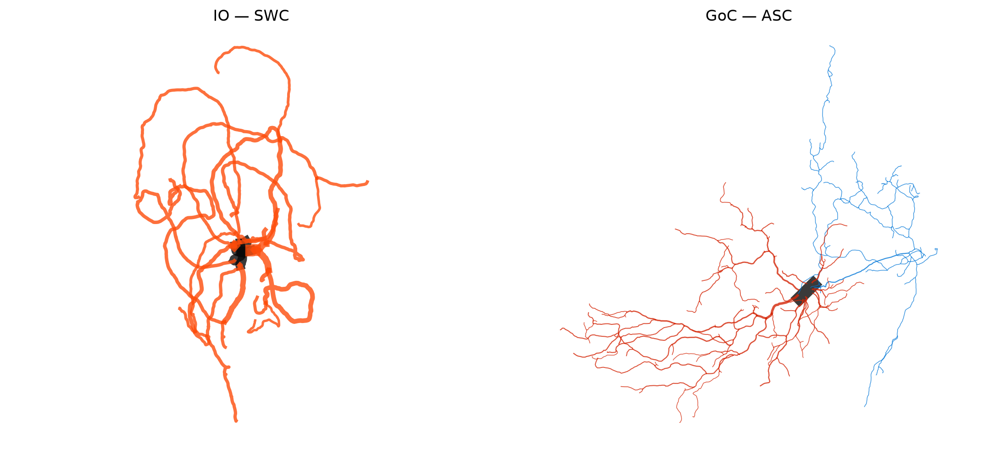

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, morpho, title in zip(axes, (io, goc), ("IO — SWC", "GoC — ASC")):
    bvm.plot2d(morpho, layout="projected", shape="line", ax=ax)
    ax.set_title(title)
fig.tight_layout()
ingestion_path = save_figure(fig, "ingestion_comparison.png")
plt.close(fig)
display(Image(filename=ingestion_path))

## Part 2 — 2D and 3D morphology views

The 2D API separates the underlying morphology from its presentation. `projected` preserves a physical coordinate plane, while `stem`, `balloon`, and `radial_360` expose tree structure with different layout strategies. The same morphology can also be rendered as full 3D geometry or as a lightweight skeleton.

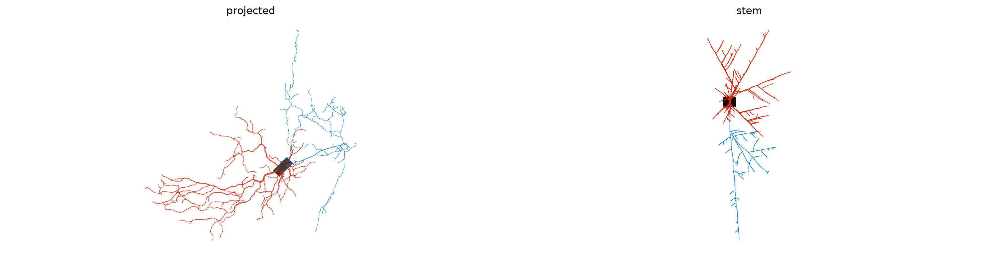

In [4]:
layouts = ("projected", "stem") # , "balloon", "radial_360"
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))

for ax, layout in zip(axes, layouts):
    bvm.plot2d(goc, layout=layout, shape="line", ax=ax)
    ax.set_title(layout)

fig.tight_layout()
layout_path = save_figure(fig, "layout_gallery.png")
plt.close(fig)
display(Image(filename=layout_path))

~/braintools/braintools/visualize/morphology/backend_pyvista.py:255: PyVistaDeprecationWarning: Plotter.export_html is deprecated. Use plotter.trame.export_html(...) instead. Install via `pip install trame-pyvista`.
  exported = plotter.export_html(filename=None)


<interactive PyVista scene>
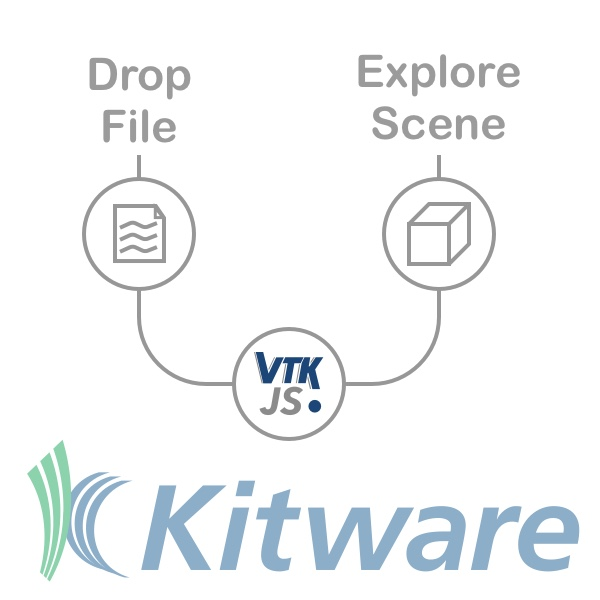

In [5]:
# The static capture was rendered out-of-process with:
bvm.plot3d(io, mode="geometry", backend="pyvista", jupyter_backend='html')

### High-resolution rotating 3D captures

The interactive view above is retained for inspection. The helper below renders a presentation-ready GIF by orbiting the camera around the morphology's vertical (Y) axis. Parallel projection and a fixed fit keep the apparent scale stable as the view moves from front to side to back. With parallel projection, `zoom` controls the apparent size while `camera_distance_factor` mainly controls camera and clipping distance.

In [6]:
import numpy as np
from PIL import Image as PILImage
from IPython.utils.capture import capture_output


def save_rotating_morphology_gif(
    morpho,
    filename,
    *,
    window_size=(1280, 960),
    n_frames=120,
    fps=30,
    start_angle_deg=90.0,
    rotation_deg=360.0,
    elevation_deg=8.0,
    camera_distance_factor=3.0,
    zoom=1.0,
    fit_margin=1.06,
    mode="geometry",
):
    """Render a smooth, upright Y-axis orbit as an animated GIF."""
    if n_frames < 2 or not 0 < fps <= 100:
        raise ValueError("n_frames must be >= 2 and fps must be in (0, 100].")
    if not -89 < elevation_deg < 89:
        raise ValueError("elevation_deg must be between -89 and 89.")
    if camera_distance_factor <= 0 or zoom <= 0 or fit_margin <= 0:
        raise ValueError("Camera distance, zoom, and fit margin must be positive.")

    output_path = OUTPUT / filename
    plotter = None
    try:
        with capture_output(), redirect_stderr(StringIO()):
            plotter = bvm.plot3d(
                morpho, mode=mode, backend="pyvista", notebook=False
            )
            plotter.set_background("white")
            plotter.hide_axes()
            plotter.window_size = window_size
            plotter.show(auto_close=False, interactive=False)

        bounds = np.array([
            [plotter.bounds.x_min, plotter.bounds.x_max],
            [plotter.bounds.y_min, plotter.bounds.y_max],
            [plotter.bounds.z_min, plotter.bounds.z_max],
        ], dtype=float)
        center = bounds.mean(axis=1)
        corners = np.array([
            [x, y, z]
            for x in bounds[0]
            for y in bounds[1]
            for z in bounds[2]
        ])
        radius = np.linalg.norm(bounds[:, 1] - bounds[:, 0]) / 2.0
        camera_distance = max(radius * camera_distance_factor, 1.0)
        aspect = window_size[0] / window_size[1]
        elevation = np.deg2rad(elevation_deg)
        angles = np.linspace(
            start_angle_deg,
            start_angle_deg + rotation_deg,
            n_frames,
            endpoint=False,
        )

        world_up = np.array([0.0, 1.0, 0.0])
        camera_poses = []
        required_scales = []
        for angle_deg in angles:
            angle = np.deg2rad(angle_deg)
            radial = np.array([
                np.cos(angle) * np.cos(elevation),
                np.sin(elevation),
                np.sin(angle) * np.cos(elevation),
            ])
            camera_position = center + camera_distance * radial
            forward = center - camera_position
            forward /= np.linalg.norm(forward)
            camera_up = world_up - np.dot(world_up, forward) * forward
            camera_up /= np.linalg.norm(camera_up)
            camera_right = np.cross(forward, camera_up)
            camera_right /= np.linalg.norm(camera_right)

            relative_corners = corners - center
            half_height = np.max(np.abs(relative_corners @ camera_up))
            half_width = np.max(np.abs(relative_corners @ camera_right))
            required_scales.append(max(half_height, half_width / aspect))
            camera_poses.append((camera_position, camera_up))

        parallel_scale = max(required_scales) * fit_margin / zoom
        frames = []
        for camera_position, camera_up in camera_poses:
            plotter.camera_position = [
                tuple(camera_position), tuple(center), tuple(camera_up)
            ]
            plotter.camera.parallel_projection = True
            plotter.camera.parallel_scale = parallel_scale
            plotter.reset_camera_clipping_range()
            plotter.render()
            frame = plotter.screenshot(return_img=True)
            frames.append(PILImage.fromarray(frame).convert("RGB"))

        # GIF delays are stored in centiseconds; distribute rounding error
        # so the complete loop still has the requested average frame rate.
        frame_ends_cs = np.rint(np.arange(1, n_frames + 1) * 100 / fps).astype(int)
        frame_starts_cs = np.concatenate(([0], frame_ends_cs[:-1]))
        durations_ms = np.maximum(frame_ends_cs - frame_starts_cs, 1) * 10
        frames[0].save(
            output_path,
            save_all=True,
            append_images=frames[1:],
            duration=durations_ms.tolist(),
            loop=0,
            disposal=2,
            optimize=False,
        )
    finally:
        if plotter is not None:
            plotter.close()

    return output_path

IO rotating 3D:  ../_static/single_cell_frontend/io_3d_rotation.gif


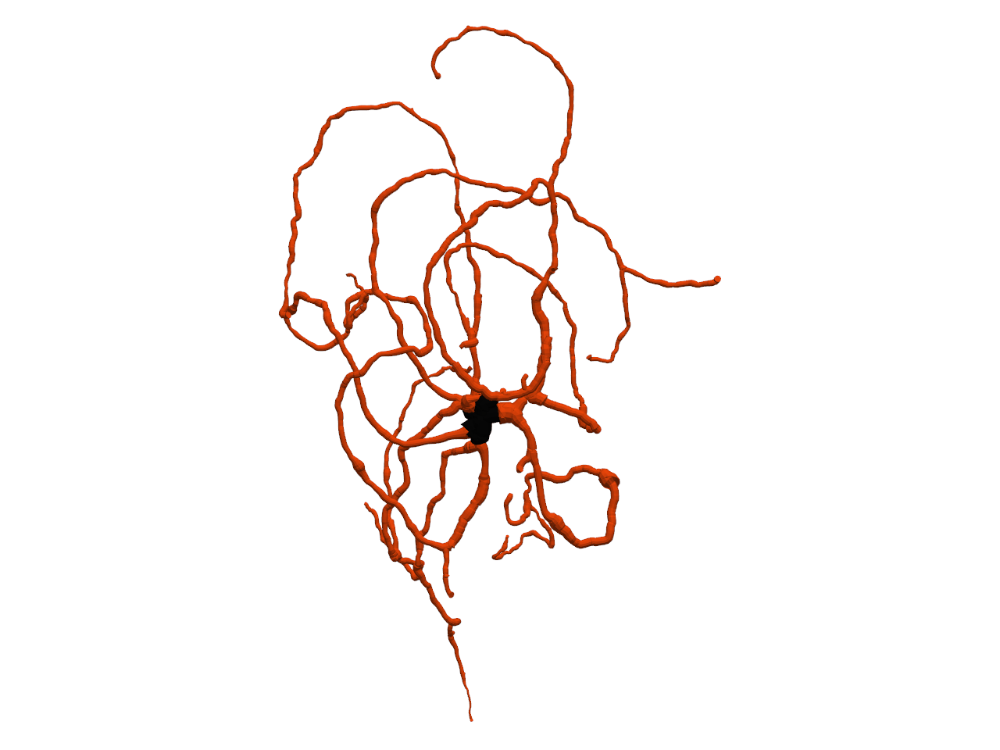

GoC rotating 3D: ../_static/single_cell_frontend/goc_3d_rotation.gif


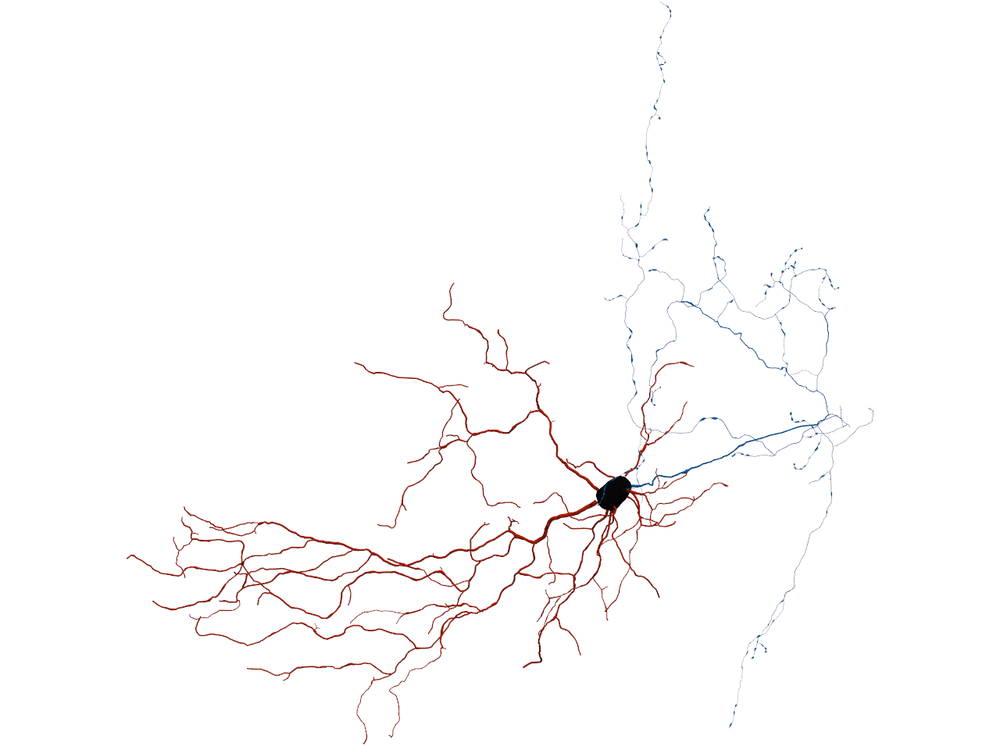

In [7]:
# Presentation-quality defaults. Reduce size/frames/fps for a quicker draft.
GIF_WINDOW_SIZE = (1280, 960)
GIF_N_FRAMES = 120
GIF_FPS = 30
GIF_START_ANGLE_DEG = 90.0
GIF_ROTATION_DEG = 360.0
GIF_ELEVATION_DEG = 8.0
GIF_CAMERA_DISTANCE_FACTOR = 3.0
GIF_FIT_MARGIN = 1.06

common_gif_options = dict(
    window_size=GIF_WINDOW_SIZE,
    n_frames=GIF_N_FRAMES,
    fps=GIF_FPS,
    start_angle_deg=GIF_START_ANGLE_DEG,
    rotation_deg=GIF_ROTATION_DEG,
    elevation_deg=GIF_ELEVATION_DEG,
    camera_distance_factor=GIF_CAMERA_DISTANCE_FACTOR,
    fit_margin=GIF_FIT_MARGIN,
)
io_gif_path = save_rotating_morphology_gif(
    io, "io_3d_rotation.gif", zoom=1.08, **common_gif_options
)
goc_gif_path = save_rotating_morphology_gif(
    goc, "goc_3d_rotation.gif", zoom=1.20, **common_gif_options
)

print(f"IO rotating 3D:  {io_gif_path}")
display(Image(filename=io_gif_path, width=800))
print(f"GoC rotating 3D: {goc_gif_path}")
display(Image(filename=goc_gif_path, width=800))

## Part 3 — Branch, control-volume, and runtime-node topology

A single morphology supports several useful abstraction levels. Branch views emphasize biological tree structure; control-volume views show discretization; runtime-node views expose the graph consumed by mechanisms. The cell is initialized only to build these structures—no time stepping is performed.

In [8]:
soma = branch_in("type", "soma")
dendrites = branch_in("type", "dendrite")
thick = branch_range("mean_radius", (0.4 * u.um, None), closed="neither", )

sites = RootLocation(0.5) | Terminals()

cell = Cell(goc, cv_policy=MaxCVLen(40 * u.um))
cell.paint(
    AllRegion(),
    mech.Channel("IL", g_max=0.03 * u.mS / u.cm**2, E=-70 * u.mV),
)
cell.paint(
    dendrites,
    mech.Channel("Na_HH1952", g_max=120 * u.mS / u.cm**2),
)
cell.place(
    sites,
    mech.Synapse("ExpSyn", tau=2 * u.ms, e=0 * u.mV),
)
cell.init_state()

print(f"branches: {cell.morpho.n_branches}")
print(f"control volumes: {cell.n_cv}")
print(f"runtime nodes: {len(cell.node_tree.nodes)}")
print(f"paint rules: {len(cell.paint_rules)}; place rules: {len(cell.place_rules)}")

branches: 227
control volumes: 309
runtime nodes: 537
paint rules: 3; place rules: 1


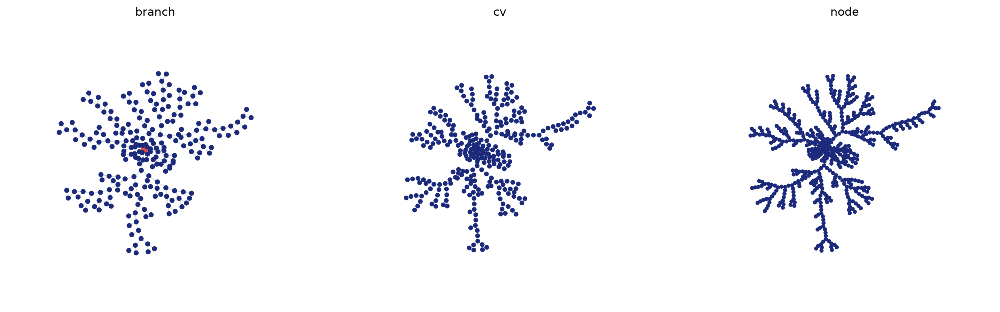

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, level in zip(axes, ("branch", "cv", "node")):
    bvm.plot_topology_graph(
        cell.topology_data(level, region=soma),
        layout="kamada_kawai",
        ax=ax,
    )
    ax.set_title(level)

fig.tight_layout()
topology_path = save_figure(fig, "topology_levels.png")
plt.close(fig)
display(Image(filename=topology_path))

## Part 4 — Regions, locations, and model decoration

BrainCell follows the same separation of concerns used by Arbor's [regions and locsets](https://docs.arbor-sim.org/en/latest/concepts/labels.html): a region describes a continuous part of the cable tree, while a locset describes discrete sites. `paint` assigns distributed mechanisms to regions and `place` assigns point mechanisms to locations. The expressions stay reusable across visualization and model construction.

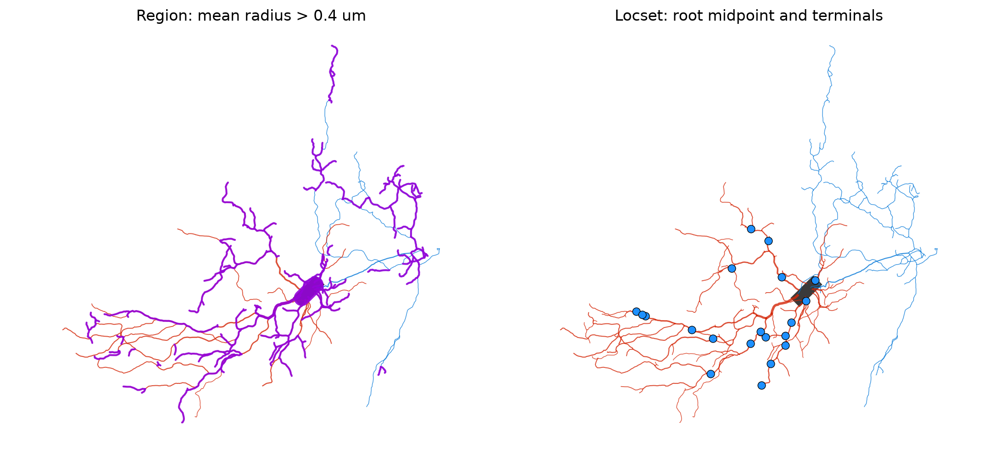

In [10]:
from braincell.filter import AllRegion, RandomSamples
dendrite_mask = goc.select(dendrites)


site_mask = goc.select(sites)

random_sampling = RandomSamples(
    region=thick,
    count=20,
    seed=42,
)
random_sampling_mask = goc.select(random_sampling)

long = branch_range("length", (None,40 * u.um,), closed="neither", )
thick_mask = goc.select(thick)

long_mask = goc.select(long)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
bvm.plot2d(goc, layout="projected", shape="line", region=long_mask, ax=axes[0])
axes[0].set_title("Region: mean radius > 0.4 um")
bvm.plot2d(goc, layout="projected", shape="line", locset=random_sampling_mask, ax=axes[1])
axes[1].set_title("Locset: root midpoint and terminals")


fig.tight_layout()
selection_path = save_figure(fig, "region_locset_overlays.png")
plt.close(fig)
display(Image(filename=selection_path))

### Placing synapses on a locset

The same locset used for visualization can be passed directly to `Cell.place`. This example places one `ExpSyn` instance at the GoC root midpoint and at every terminal location.

In [11]:
synapse_cell = Cell(goc, cv_policy=MaxCVLen(40 * u.um))
synapse_cell.place(
    sites,
    mech.Synapse(
        "ExpSyn",
        name="selected_exp_syn",
        tau=2 * u.ms,
        e=0 * u.mV,
    ),
)
synapse_cell.init_state()

synapse_layout = next(
    layout for layout in synapse_cell.layouts
    if layout.kind == "synapse:ExpSyn"
)
print(f"Selected locset locations: {len(site_mask.points)}")
print(f"Placed ExpSyn instances: {synapse_layout.n_active}")

Selected locset locations: 120
Placed ExpSyn instances: 120


### Callable channel distributions

A density-mechanism parameter can be a callable instead of a constant. BrainCell passes a read-only `CVContext` to the callable and resolves it once per active CV during `init_state()`. Here, dendritic sodium conductance follows a sigmoid profile over path distance from the soma surface; the same callable declaration remains one runtime layout.

In [12]:
import numpy as np

G_MAX_UNIT = u.mS / u.cm**2

def gmax_from_distance(distance):
    distance_um = distance.to_decimal(u.um)
    return (20.0 + 0.15 * distance_um) * G_MAX_UNIT

def gmax_from_distance_sigmoid(distance):
    distance_um = distance.to_decimal(u.um)
    
    # 基础参数（可根据需要调整）
    g_min = 20.0    # 近端最小电导密度 (S/cm²)
    g_max = 100.0  # 远端最大电导密度 (S/cm²)
    d_0 = 150.0     # 半激活距离 (µm)，即密度上升到一半时的位置
    k = 0.05        # 陡峭度参数 (1/µm)，控制曲线上升的快慢
    
    g_value = g_min + (g_max - g_min) / (1 + np.exp(-k * (distance_um - d_0)))
    
    return g_value * G_MAX_UNIT

def dendritic_na_gmax(context):
    return gmax_from_distance_sigmoid(context.path_distance_from_soma)

distance_cell = Cell(goc, cv_policy=MaxCVLen(40 * u.um))
distance_cell.paint(
    AllRegion(),
    mech.Channel("IL", g_max=0.03 * G_MAX_UNIT, E=-70 * u.mV),
)
distance_cell.paint(
    dendrites,
    mech.Channel(
        "Na_HH1952",
        name="na_distance",
        g_max=dendritic_na_gmax,
    ),
)
distance_cell.init_state()

dendrite_contexts = [
    context
    for context in distance_cell.cv_contexts
    if context.branch_type == "dendrite"
]
print(f"callable evaluated on {len(dendrite_contexts)} dendritic CVs")

callable evaluated on 207 dendritic CVs


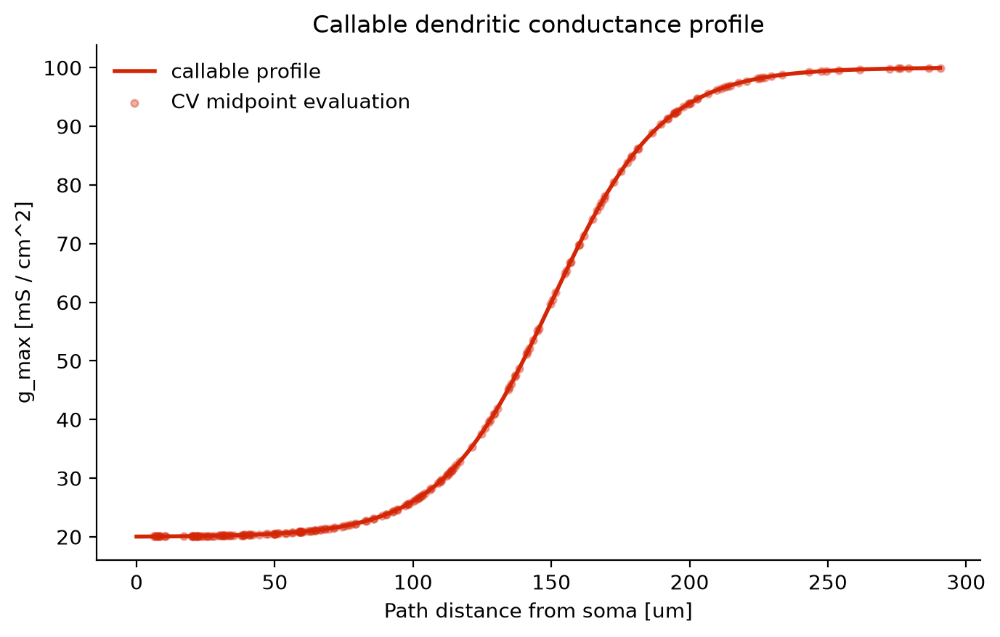

In [13]:
cv_distance_um = np.asarray([
    context.path_distance_from_soma.to_decimal(u.um)
    for context in dendrite_contexts
], dtype=float)
cv_gmax = np.asarray([
    dendritic_na_gmax(context).to_decimal(G_MAX_UNIT)
    for context in dendrite_contexts
], dtype=float)

distance_um = np.linspace(0.0, cv_distance_um.max(), 240)
curve_gmax = gmax_from_distance_sigmoid(distance_um * u.um).to_decimal(G_MAX_UNIT)
dendrite_color = bvm.get_defaults().branch_type_colors["dendrite"]
if not isinstance(dendrite_color, str):
    dendrite_color = np.asarray(dendrite_color, dtype=float)
    if dendrite_color.max() > 1.0:
        dendrite_color = dendrite_color / 255.0

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    distance_um,
    curve_gmax,
    color=dendrite_color,
    linewidth=2.0,
    label="callable profile",
)
ax.scatter(
    cv_distance_um,
    cv_gmax,
    color=dendrite_color,
    s=12,
    alpha=0.35,
    label="CV midpoint evaluation",
)
ax.set_xlabel("Path distance from soma [um]")
ax.set_ylabel("g_max [mS / cm^2]")
ax.set_title("Callable dendritic conductance profile")
ax.legend(frameon=False)
fig.tight_layout()
curve_path = save_figure(fig, "gmax_callable_curve.png")
plt.close(fig)
display(Image(filename=curve_path))

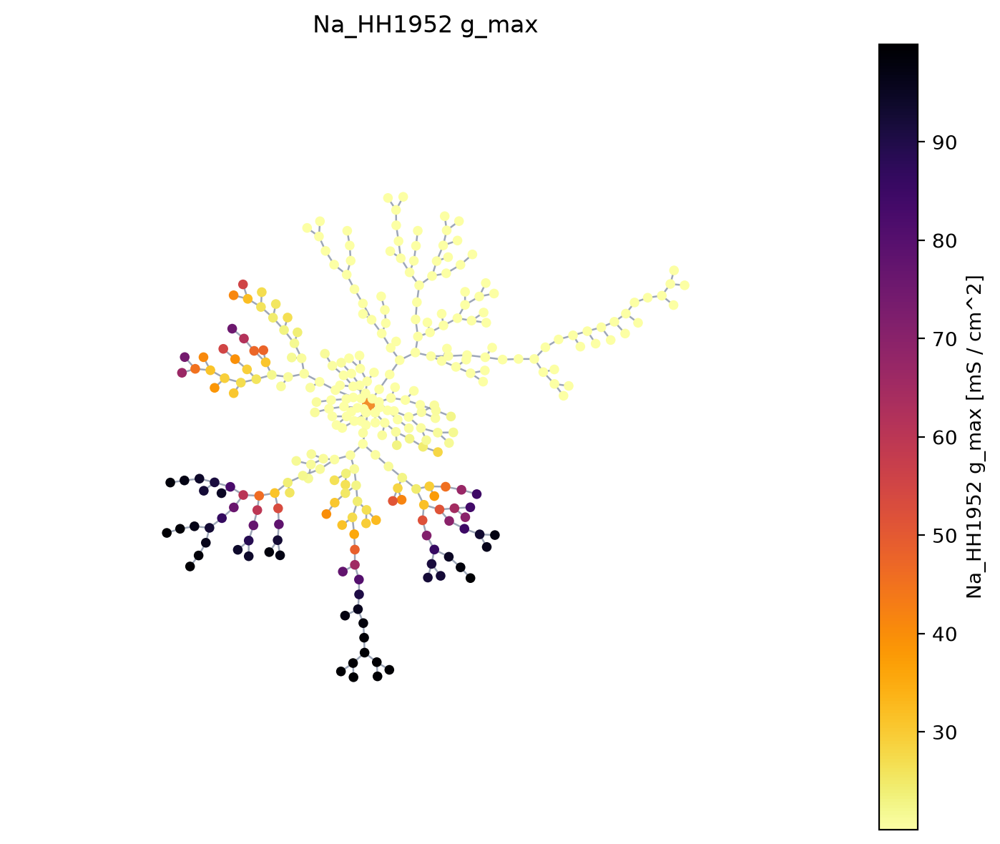

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
bvm.plot_topology_graph(
    distance_cell.topology_data("cv", value=("channel", "Na_HH1952", "g_max")),
    layout="kamada_kawai",
    cmap="inferno_r",
    vmin=float(cv_gmax.min()),
    vmax=float(cv_gmax.max()),
    value_label="Na_HH1952 g_max",
    ax=ax,
)

ax.set_title("Na_HH1952 g_max")
fig.tight_layout()
heatmap_path = save_figure(fig, "gmax_callable_dendrite_heatmap.png")
plt.close(fig)
display(Image(filename=heatmap_path))

## Part 5 — Current interaction boundary

`VisHooks` already provides backend-independent pick, hover, and leave callbacks. With an interactive Matplotlib backend (for example `%matplotlib widget`) or PyVista picking, a callback receives branch identity, segment identity, fractional branch position, and the scene position. The cell below also executes under a non-interactive documentation backend; interaction begins when the notebook uses an interactive frontend.

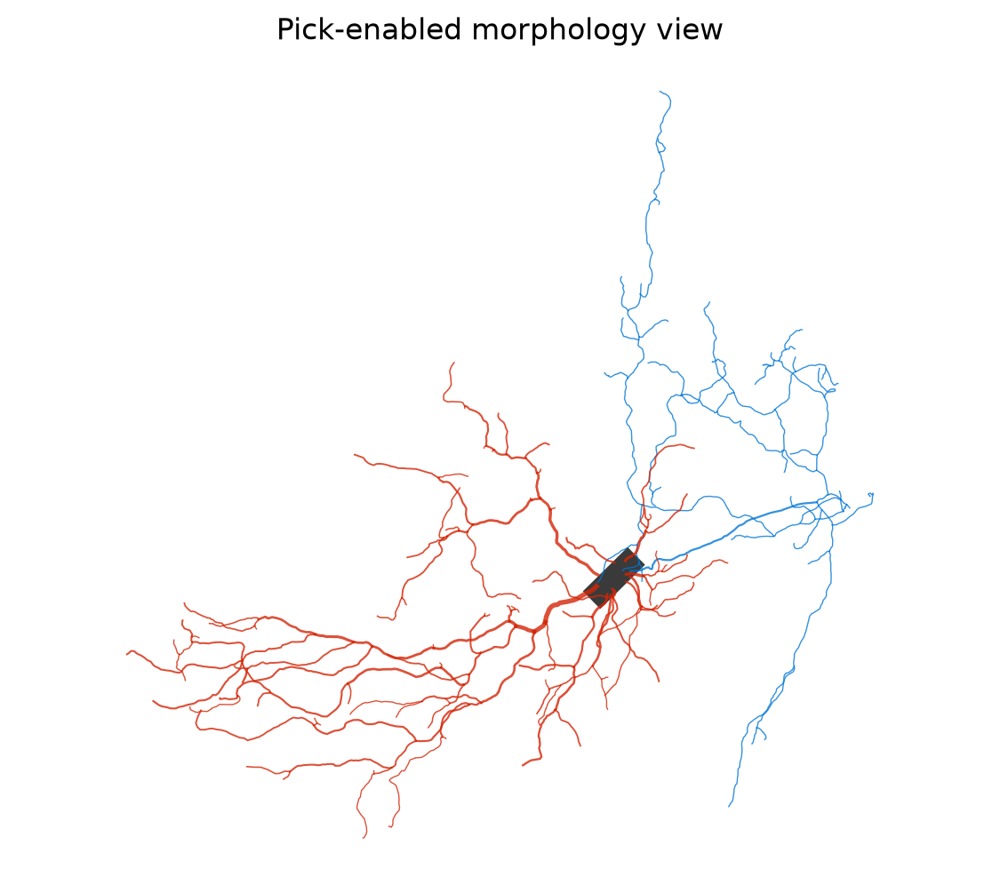

Pick callback registered; use an interactive backend to receive events.


In [15]:
def report_pick(info):
    print(info.branch_name, info.branch_type, info.segment_index, info.x)

hooks = bvm.VisHooks(on_pick=report_pick)
fig, ax = plt.subplots(figsize=(7, 6))
bvm.plot2d(goc, layout="projected", shape="line", hooks=hooks, ax=ax)
ax.set_title("Pick-enabled morphology view")
interaction_path = save_figure(fig, "interaction_entrypoint.png")
plt.close(fig)
display(Image(filename=interaction_path))
print("Pick callback registered; use an interactive backend to receive events.")

### Next interaction milestones

The event channel is present, but BrainCell does not yet provide a persistent editor. The next frontend work should preserve the programmatic model as the source of truth and add two explicit workflows:

1. **Morphology editing** — persistent multi-selection; insert, delete, move, and resize nodes or subtrees; validation; before/after comparison; undo/redo; and SWC/ASC or Python export. [NeuroEditor](https://pmc.ncbi.nlm.nih.gov/articles/PMC10902916/) is a direct reference for selection, correction, and before/after inspection. The [TREES Toolbox](https://pmc.ncbi.nlm.nih.gov/articles/PMC7612393/) is a mature reference for tree construction and manipulation.
2. **Mechanism and synapse editing** — synchronized morphology and topology views; visual RegionExpr/LocsetExpr construction; channel-parameter distributions; synapse placement; and export to `paint`/`place` declarations. [DendroTweaks](https://elifesciences.org/articles/103324) is the primary reference for linked views and interactive subcellular parameter distributions.

These are roadmap targets, not implemented APIs. The current executable boundary remains morphology ingestion, declarative selection and decoration, multi-level visualization, and event callbacks.